# Week 6: Instrumental Variables

This notebook follows the Week 6 page, in the same order:
<https://yoonismo.github.io/causal-computing/week6.html>

Read the explanations on the page and run the cells here **in order** from top to bottom. Write your answers to the questions in the empty text cells.

## 0. Before you start

- Check **Select Kernel** at the top right: it should say **ECON 481 (Python 3.12)**.
- If a cell fails with `ModuleNotFoundError`, a package is missing from your environment. See `README.md`.
- The data sets come with the `causaldata` package, so you need an internet connection only to install the packages.
- Every cell must run from top to bottom when you push: GitHub runs this notebook after every push.

First, the packages and the random seed. `linearmodels` is new this week: it has a 2SLS function with correct standard errors.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from linearmodels.iv import IV2SLS

rng = np.random.default_rng(481)

## From Week 4 to Week 6

In Week 4 we identified causal effects with assumptions about **observed** variables: unconfoundedness given $X$. However, we often need to consider **unobserved** variables that are involved in people's decision making process and also affect the outcome. In that case, we cannot identify the causal parameters of interest.

Instrumental variables (IV) take a different route: find a variable $Z$ that moves the treatment $D$ for reasons that have nothing to do with the potential outcomes, and use **only** the part of the variation in $D$ that comes from $Z$. 

We follow Chapter 7 of Cunningham's *Causal Inference: The Mixtape*.

## Instrumental variables

### The idea: the Vietnam draft lottery

Did serving in the military during the Vietnam War affect men's later earnings? Comparing veterans with non-veterans mixes the effect of service with the reasons men served. 

Angrist (1990) used the draft lottery instead. In each lottery, every birth date received a random sequence number (RSN) from 1 to 365. Men were called for induction in RSN order up to a ceiling set by the Defense Department, so only men with numbers below the ceiling could be drafted; Angrist calls them **draft-eligible**. The ceilings were 195 in the 1970 lottery, 125 in 1971 and 95 in 1972 (Angrist, Chen and Song, 2011).

Draft eligibility is not the same as service. Some draft-eligible men avoided service through deferments, poor health or low test scores, and many men with numbers above the ceiling volunteered (Angrist, Chen and Song, 2011). So we have three variables:

- $Z_i$: draft eligibility, binary, the **instrument** (randomly assigned),
- $D_i$: military service, binary, the **treatment** (partly chosen),
- $Y_i$: earnings, the **outcome**,

where

$$
\begin{align*}
Z_i &= \begin{cases} 1 & \text{if } i \text{ receives a number below the ceiling number,} \\ 0 & \text{otherwise,} \end{cases} \\[6pt]
D_i &= \begin{cases} 1 & \text{if } i \text{ served in the military,} \\ 0 & \text{otherwise.} \end{cases}
\end{align*}
$$

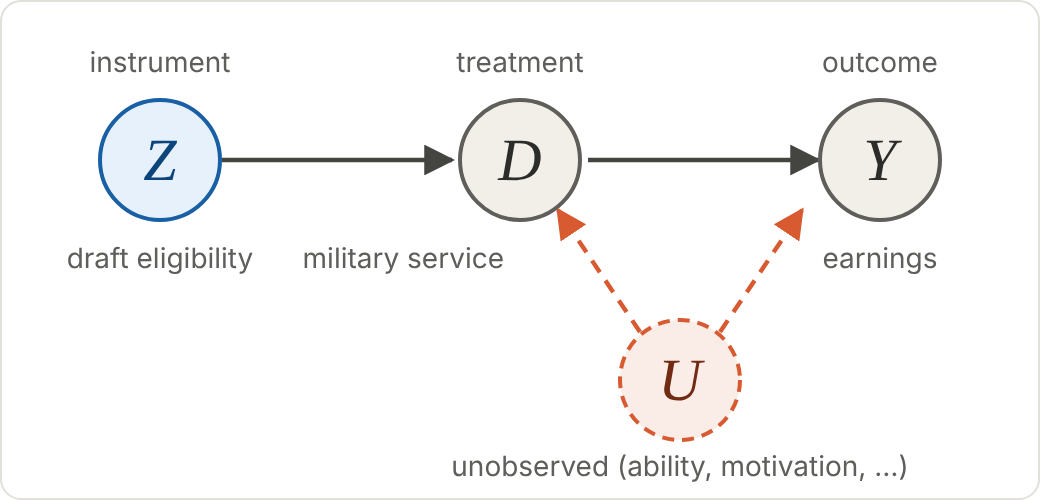

$U$ stands for everything unobserved that affects both service and earnings. Because of $U$, comparing $Y$ across $D$ is biased. Why? The lottery number was drawn at random, so $Z$ is not connected to $U$.

## Omitted variable bias
Let's review omitted variable bias. Consider the following true linear regression model: 

$$
    Y_i = \alpha + \delta D_i + \gamma U_i + \epsilon_i, 
$$

where

- $U_i$: relevant, but unobserved variable that affects both $D_i$ and $Y_i$.
- $D_i$: treatment variable that depends on $U_i$ (and on other things),
- $Y_i$: outcome variable depending on both $D_i$ and $U_i$.

Since $U_i$ is unobserved, our regression model becomes 

$$
    Y_i = \alpha + \delta D_i + \xi_i
$$

where $\xi_i = \gamma U_i + \epsilon_i$. Without $U_i$, we can only compare

$$
E[Y_i \mid D_i = 1] - E[Y_i \mid D_i = 0] = \tau_{\text{ATE}} + \underbrace{\gamma \big(E[U_i \mid D_i =1] - E[U_i \mid D_i =0]\big)}_{\text{omitted variable bias}}.
$$

This means that bias arises if an unobserved variable $U_i$ differs on average between the treatment group and the control group. The derivation is on the Week 6 page.

Then how do we identify $\delta$? 

## Lab 1 — Omitted variable bias by hand

We simulate 10,000 people. $U_i$ is an unobserved trait (think of it as ability or motivation). The instrument is a fair coin. Service depends on the instrument **and** on $U_i$, and earnings depend on service **and** on $U_i$:

$$
\begin{align*}
Z_i &\sim \text{Bernoulli}(0.5), \qquad U_i, \eta_i, \varepsilon_i \sim N(0, 1) \text{ independent}, \\
D_i &= \mathbf{1}\{-0.5 + 1.0\, Z_i + U_i + \eta_i > 0\}, \\
Y_i &= 1 + \tau D_i + 2 U_i + \varepsilon_i, \qquad \tau = 2.
\end{align*}
$$

The effect $\tau = 2$ is the same for everyone, and $Z_i$ enters $Y_i$ only through $D_i$. This is the model above with $\alpha = 1$, $\gamma = 2$ and $\delta = \tau = 2$.

In [ ]:
n, tau = 10_000, 2
u = rng.normal(0, 1, n)                                   # unobserved trait
z = rng.binomial(1, 0.5, n)                               # the instrument: a fair coin
d = (-0.5 + 1.0 * z + u + rng.normal(0, 1, n) > 0).astype(int)
y = 1 + tau * d + 2 * u + rng.normal(0, 1, n)
sim = pd.DataFrame({"y": y, "d": d, "z": z})
naive = y[d == 1].mean() - y[d == 0].mean()
print("Difference in means by D (OLS slope):", round(naive, 3), "  (true effect:", tau, ")")

We can see this using naïve OLS.

In [ ]:
var_d_hat = sum((d-np.mean(d))**2)/(n-1)
cov_y_d_hat = ((y - np.mean(y)) @ (d - np.mean(d))) / (n - 1) 

naive_delta_ols = cov_y_d_hat/var_d_hat
print("naive OLS: ", naive_delta_ols, "bias: ", naive_delta_ols - tau)

## put ols using smf
naive_smf_ols = smf.ols("y ~ d", data=sim).fit()                 # OLS of Y on D

round(naive_smf_ols.params, 3)

**Question 1.** Why is the difference in means by $D$ above 2?

*Your answer to Question 1:*

Is there any way to remove the omitted variable bias? 

## The Wald estimator

It is time to use the IV approach. Assume that we have an IV $Z$. Then what assumptions for IV do we need to identify $\delta$? 

- Exclusion restriction: $Z$ must affect the outcome variable $Y$ only through the problematic variable $D$. 
- Independence: $Z$ is independent of both unobserved variable $U$ and error term $\epsilon$. 
- Relevance (nonzero first stage): $\text{Cov}[D_i, Z_i] \neq 0$, so that we can divide by it.

The intuition of the IV strategy is that we use the variation in $Y$ and in $D$ induced by $Z$. 

$$
    \tau_{\text{ATE}} = \frac{\text{Cov}[Y_i, Z_i]/ \text{Var}[Z_i]}{\text{Cov}[D_i, Z_i]/ \text{Var}[Z_i]} =\frac{\text{Cov}[Y_i, Z_i]}{\text{Cov}[D_i, Z_i]}
$$

This holds because the effect $\delta$ is the same for everyone, so $\delta = \tau_{\text{ATE}}$. When effects differ across people, the same ratio is the average effect for a particular group, not the ATE (see the LATE section).

### Simulation

In [ ]:
print("Cov(Y, Z) / Cov(D, Z):", round(np.cov(y, z)[0, 1] / np.cov(d, z)[0, 1], 3))

## Lab 2 — Two-stage least squares (2SLS)

The same number comes from two regressions. **Stage 1:** regress $D_i$ on $Z_i$ and keep the fitted values $\hat D_i$, the part of $D_i$ explained by the instrument. **Stage 2:** regress $Y_i$ on $\hat D_i$. With one binary instrument and no covariates, the stage-2 slope is exactly the Wald ratio.

Doing the two stages by hand gives the right coefficient but the **wrong standard error**. A package does it correctly.

In [ ]:
stage1 = smf.ols("d ~ z", data=sim).fit()                 # stage 1
sim["d_hat"] = stage1.fittedvalues
stage2 = smf.ols("y ~ d_hat", data=sim).fit()             # stage 2, by hand

iv = IV2SLS.from_formula("y ~ 1 + [d ~ z]", data=sim).fit(cov_type="robust")

print("2SLS by hand: coefficient", round(stage2.params["d_hat"], 3), "  standard error", round(stage2.bse["d_hat"], 3))
print("IV2SLS:       coefficient", round(iv.params["d"], 3), "  standard error", round(iv.std_errors["d"], 3))

**Question 2.** The two coefficients are the same but the standard errors are not. In stage 2 by hand, which residual does OLS use to estimate the error variance, $Y_i - \hat\alpha - \hat\tau \hat D_i$ or $Y_i - \hat\alpha - \hat\tau D_i$? Which one belongs to the model $Y_i = \alpha + \tau D_i + e_i$?

*Your answer to Question 2:*

## Local Average Treatment Effect (LATE)

So far, we were able to use the Wald IV estimator and 2SLS based on a critical, and yet not plausible assumption that the individual treatment effect (ITE) is equal across people. However, that does not make much sense. Then if the ITE differs across people, how do we identify the treatment effect? Most importantly, in this case, what effect do we identify through the ratio of two effects, the effect of an IV on the outcome in the numerator and the effect of an IV on the treatment in the denominator? 

### When effects differ

In Lab 1 everyone had the same effect. In reality the effect of service, or of schooling, differs across people. In other words, 
$$
    \delta_i = Y_i(1) - Y_i(0)
$$
One can say that the treatment effect is heterogeneous when the ITE differs across units. If you think about it, this is a more natural assumption. People receive different treatment effects due to their demographics (observables) and culture and/or philosophy (unobservables). 

Since the treatment assignment is not random due to such observables and unobservables, it is difficult to identify the true treatment effect. The IV strategy enables us to use the randomness to explain the variation in the treatment. However, two of the assumptions for a valid IV is that 

- one, it must be relevant to the treatment, and 
- two, any effect of a candidate IV on the outcome must be via the treatment variable. 

This means that there is a mechanism through wich people react to the IV: depending on the realization of randomness represented by an IV, people "decide." That is, people can "comply" with the realization, or react in the opposite way, or in many different ways. To explain and represent it, what framework do we need? As a result, what does the Wald ratio estimate under this framework? 

Imbens and Angrist (1994) gave the answer.

### Potential outcomes and potential treatment status

We use the notation of the Mixtape. For a binary instrument $Z_i \in \{0, 1\}$ and binary treatment $D_i \in \{0, 1\}$:

- **Potential treatment status:** $D_i^1$ is $i$'s treatment status when $Z_i = 1$, and $D_i^0$ when $Z_i = 0$.\
  We observe $D_i = Z_i D_i^1 + (1 - Z_i) D_i^0$.
- **Potential outcomes** have two arguments, the treatment and the instrument: $Y_i(d, z)$. We observe $Y_i = Y_i(D_i, Z_i)$.

### Four types of people

Each person has a pair $(D_i^1, D_i^0)$: what they would do with and without the instrument. There are four possible pairs:

| type | $D_i^1$ | $D_i^0$ | meaning | in the draft example |
|---|---|---|---|---|
| complier | 1 | 0 | follows $Z_i$ | serves only if draft-eligible |
| always-taker | 1 | 1 | always do | volunteers anyway |
| never-taker | 0 | 0 | always don't | never serves (e.g., a medical exemption) |
| defier | 0 | 1 | react in the opposite to $Z_i$ | serves only if **not** draft-eligible |

We never see both $D_i^1$ and $D_i^0$ for the same person, so we cannot tell each person's type from the data.

### The five assumptions

1. **SUTVA.** Person $i$'s treatment status and outcome depend only on $i$'s own instrument and treatment, not on other people's.
2. **Independence.** The instrument is as good as randomly assigned:
$$\big\{Y_i(D_i^1, 1),\ Y_i(D_i^0, 0),\ D_i^1,\ D_i^0\big\} \perp Z_i.$$
3. **Exclusion restriction.** The instrument affects the outcome only through the treatment:
$$Y_i(D_i, 0) = Y_i(D_i, 1) \quad \text{for } D = 0, 1.$$
Then we can drop the $z$ argument and write $Y_i(1)$ and $Y_i(0)$, as before. (The Mixtape writes $Y_i^1$ and $Y_i^0$.)
4. **Nonzero first stage.** $E[D_i^1 - D_i^0] \neq 0$.
5. **Monotonicity.** The instrument moves everyone in the same direction, or not at all: $D_i^1 \geq D_i^0$ for all $i$ (or $D_i^1 \leq D_i^0$ for all $i$). With $\geq$, there are no defiers.

### The LATE theorem

Under the five assumptions, the Wald IV estimator identifies the average treatment effect for the units who **comply** with the random assignment. This is what "local" means. It says nothing about always-takers or never-takers.

$$
\tau_{\text{LATE}}^{\text{Wald}} = \frac{E[Y_i \mid Z_i = 1] - E[Y_i \mid Z_i = 0]}{E[D_i \mid Z_i = 1] - E[D_i \mid Z_i = 0]}
= E\big[Y_i(1) - Y_i(0) \mid D_i^1 - D_i^0 = 1\big].
$$

## Lab 3 — LATE in a simulation

We build the four types directly (no defiers): 20% always-takers, 30% never-takers, 50% compliers. The types differ in their outcome **without** treatment (that is the selection problem) and in their effect:

| type | share | $Y_i(0)$ | effect $Y_i(1) - Y_i(0)$ |
|---|---|---|---|
| always-taker | 0.2 | $12 + \varepsilon_i$ | 3 |
| complier | 0.5 | $10 + \varepsilon_i$ | 1 |
| never-taker | 0.3 | $9 + \varepsilon_i$ | 0.5 |

with $\varepsilon_i \sim N(0, 1)$. The instrument is a fair coin, independent of the type.

In [ ]:
n = 100_000
types = rng.choice(["always", "complier", "never"], size=n, p=[0.2, 0.5, 0.3])
y0_by_type = {"always": 12, "complier": 10, "never": 9}
effect_by_type = {"always": 3, "complier": 1, "never": 0.5}

late_sim = pd.DataFrame({"type": types})
late_sim["y0"] = late_sim["type"].map(y0_by_type) + rng.normal(0, 1, n)
late_sim["y1"] = late_sim["y0"] + late_sim["type"].map(effect_by_type)
late_sim["d1"] = (late_sim["type"] != "never").astype(int)       # treatment status if Z = 1
late_sim["d0"] = (late_sim["type"] == "always").astype(int)      # treatment status if Z = 0
late_sim["z"] = rng.binomial(1, 0.5, n)
late_sim["d"] = np.where(late_sim["z"] == 1, late_sim["d1"], late_sim["d0"])
late_sim["y"] = np.where(late_sim["d"] == 1, late_sim["y1"], late_sim["y0"])
late_sim.head()

In [ ]:
effect = late_sim["y1"] - late_sim["y0"]
ate = effect.mean()
late = effect[late_sim["type"] == "complier"].mean()
att = effect[late_sim["d"] == 1].mean()

g = late_sim.groupby("z")[["d", "y"]].mean()
fs_late = g.loc[1, "d"] - g.loc[0, "d"]
wald_late = (g.loc[1, "y"] - g.loc[0, "y"]) / fs_late
ols_late = late_sim.loc[late_sim["d"] == 1, "y"].mean() - late_sim.loc[late_sim["d"] == 0, "y"].mean()

print("Truth:  ATE", round(ate, 3), "  ATT", round(att, 3), "  LATE (compliers)", round(late, 3))
print("Data:   difference in means by D", round(ols_late, 3), "  Wald", round(wald_late, 3))
print("Shares from the data: compliers", round(fs_late, 3),
      "  always-takers", round(g.loc[0, "d"], 3), "  never-takers", round(1 - g.loc[1, "d"], 3))

**Question 3.** Which of the three true effects does the Wald ratio recover? Why can the data never tell us the effect for the never-takers, whatever estimator we use?

*Your answer to Question 3:*

## Lab 4 — Data: college proximity and the return to schooling

Card (1995) asked how much an extra year of schooling raises wages. Schooling is chosen, and ability affects both schooling and wages. His instrument: whether a man grew up in a county with a four-year college (`nearc4`). Living near a college makes college cheaper, so it may raise schooling; the argument is that it affects wages **only** through schooling. The data come with the `causaldata` package (data set `close_college`): men from the National Longitudinal Survey of Young Men, with log wages in 1976.

Here the treatment is **years of education**, not a 0/1 variable. The Wald ratio is still reduced form over first stage.

In [ ]:
from causaldata import close_college

card = close_college.load_pandas().data
card["expersq"] = card["exper"] ** 2

print(card.groupby("nearc4")[["educ", "lwage"]].mean().round(3))

In [ ]:
ols = smf.ols("lwage ~ educ", data=card).fit()
fs_card = card.loc[card["nearc4"] == 1, "educ"].mean() - card.loc[card["nearc4"] == 0, "educ"].mean()
rf_card = card.loc[card["nearc4"] == 1, "lwage"].mean() - card.loc[card["nearc4"] == 0, "lwage"].mean()

controls = "exper + expersq + black + south + smsa"
iv_card = IV2SLS.from_formula("lwage ~ 1 + " + controls + " + [educ ~ nearc4]", data=card).fit(cov_type="robust")

print("OLS, no controls:      ", round(ols.params["educ"], 3))
print("Wald, no controls:     ", round(rf_card / fs_card, 3), "  (first stage", round(fs_card, 3), ", reduced form", round(rf_card, 3), ")")
print("2SLS with controls:    ", round(iv_card.params["educ"], 3), "  standard error", round(iv_card.std_errors["educ"], 3))
print("First-stage F (2SLS):  ", round(iv_card.first_stage.diagnostics.loc["educ", "f.stat"], 1))

**Question 4.** Is the 2SLS estimate larger or smaller than OLS? If ability bias pushes OLS **up**, how can 2SLS be larger? Think about whose schooling is changed by a nearby college.

*Your answer to Question 4:*

## Two common IV designs

Where do instruments come from in practice? Chapter 7 of the Mixtape describes five common designs: lotteries, judge fixed effects, Bartik instruments, fuzzy regression discontinuity, and the elasticity of demand. We look at two of them: lotteries and fuzzy regression discontinuity.

## Lab 5 — Lotteries: incentives to learn one's HIV status

Thornton (2008) ran an experiment in rural Malawi: after an HIV test, people were **randomly** offered cash incentives of different sizes to come back and learn their result, and the distance to the results center was also randomly assigned. Without any incentive, 34 percent learned their result; even the smallest incentive doubled that share. The incentive is a lottery that moves the treatment "learned HIV status" (`got`) without forcing it. The data are in `causaldata` (`thornton_hiv`).

The `causaldata` version does not include the later outcomes of the paper (such as condom purchases), so we look at the first stage and at the compliers, not at the Wald ratio.

In [ ]:
from causaldata import thornton_hiv

hiv = thornton_hiv.load_pandas().data.dropna(subset=["got", "any", "age", "hiv2004"])
by_any = hiv.groupby("any")["got"].mean()
print(by_any.round(3))
print("First stage = share of compliers:", round(by_any[1] - by_any[0], 3))
print("Always-takers:", round(by_any[0], 3), "  never-takers:", round(1 - by_any[1], 3))

LATE is the effect for the compliers, but we cannot point to any single complier. We **can** describe them on average. Under independence and monotonicity, for any characteristic $X_i$ measured before the instrument,

$$
E[X_i \mid \text{complier}] = \frac{E[X_i D_i \mid Z_i = 1] - E[X_i D_i \mid Z_i = 0]}{E[D_i \mid Z_i = 1] - E[D_i \mid Z_i = 0]}.
$$

In [ ]:
def complier_mean(x, d, z):
    xd = x * d
    return (xd[z == 1].mean() - xd[z == 0].mean()) / (d[z == 1].mean() - d[z == 0].mean())

for col in ["age", "hiv2004"]:
    print(f"{col}: everyone {hiv[col].mean():.3f}   compliers {complier_mean(hiv[col], hiv['got'], hiv['any']):.3f}")

The incentive amount (`tinc`) is also random and takes many values: a **continuous** instrument for a binary treatment. How does the share who learned their result change with the amount?

In [ ]:
hiv["tinc_bin"] = pd.cut(hiv["tinc"], bins=[-0.01, 0, 0.5, 1, 1.5, 2, 3])
curve = hiv.groupby("tinc_bin", observed=True)["got"].agg(["mean", "size"])
print(curve.round(3))

mid = [b.mid for b in curve.index]
plt.plot(mid, curve["mean"], "o-", color="#2a78d6")
plt.ylim(0, 1)
plt.xlabel("Incentive amount (bin midpoint)")
plt.ylabel("Share who learned their result")
plt.show()

**Question 5.** Does the share who learned their result reach 1 for the largest incentives? Relate your answer to the idea that IV can identify the average effect for the **whole** population only if the instrument can push (almost) everyone into treatment.

*Your answer to Question 5:*

## Lab 6 — A first taste of fuzzy regression discontinuity

Next week is regression discontinuity (RD). Here is the link to IV. Suppose a program is **offered** to everyone whose score $R_i$ is at or above a cutoff, here $0$, but not everyone who is offered takes it, and a few below the cutoff get in anyway. The probability of treatment **jumps** at the cutoff, but not from 0 to 1. This is a **fuzzy** RD.

Near the cutoff, the offer $Z_i = \mathbf{1}\{R_i \geq 0\}$ works like an instrument. Instead of random assignment we assume that people just below and just above the cutoff are comparable (Hahn, Todd and van der Klaauw, 2001). The effect at the cutoff is the jump in the outcome divided by the jump in the treatment:

$$
\tau_{\text{FRD}} = \frac{\lim_{r \downarrow 0} E[Y_i \mid R_i = r] - \lim_{r \uparrow 0} E[Y_i \mid R_i = r]}{\lim_{r \downarrow 0} E[D_i \mid R_i = r] - \lim_{r \uparrow 0} E[D_i \mid R_i = r]}.
$$

It has the same form as the Wald ratio. We simulate:

$$
\begin{align*}
R_i &\sim \text{Uniform}(-1, 1), \qquad Z_i = \mathbf{1}\{R_i \geq 0\}, \\
D_i &= \mathbf{1}\{-0.8 + 1.4 Z_i + 0.5 R_i + U_i + V_i > 0\}, \\
Y_i &= 1 + 1.5 R_i + \tau D_i + 2 U_i + \varepsilon_i, \qquad \tau = 2.
\end{align*}
$$

In [ ]:
n = 100_000
r = rng.uniform(-1, 1, n)
z = (r >= 0).astype(int)
u = rng.normal(0, 1, n)
d = (-0.8 + 1.4 * z + 0.5 * r + u + rng.normal(0, 1, n) > 0).astype(int)
y = 1 + 1.5 * r + 2 * d + 2 * u + rng.normal(0, 1, n)
rd = pd.DataFrame({"r": r, "z": z, "d": d, "y": y})

rd["r_bin"] = pd.cut(rd["r"], bins=np.linspace(-1, 1, 41))
binned = rd.groupby("r_bin", observed=True)[["d", "y"]].mean()
mid = [b.mid for b in binned.index]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(mid, binned["d"], "o", color="#2a78d6")
axes[0].set_ylabel("Share treated")
axes[1].plot(mid, binned["y"], "o", color="#eb6834")
axes[1].set_ylabel("Average outcome")
for ax in axes:
    ax.axvline(0, color="gray", linestyle="--")
    ax.set_xlabel("Running variable R")
plt.show()

Now the two jumps. Within a window of width $h = 0.2$ on each side of the cutoff, we fit a straight line on each side and take the difference of the two lines at $R = 0$:

In [ ]:
h = 0.2
near = rd[rd["r"].abs() < h].copy()

def jump(col):
    fit = smf.ols(col + " ~ z + r + z:r", data=near).fit()
    return fit.params["z"]

jump_y, jump_d = jump("y"), jump("d")
print("Jump in the outcome:  ", round(jump_y, 3))
print("Jump in the treatment:", round(jump_d, 3))
print("Ratio:                ", round(jump_y / jump_d, 3), "  (true effect: 2)")

iv_rd = IV2SLS.from_formula("y ~ 1 + r + z:r + [d ~ z]", data=near).fit(cov_type="robust")
print("Same thing with 2SLS: ", round(iv_rd.params["d"], 3), "  standard error", round(iv_rd.std_errors["d"], 3))

**Question 6.** Which assumption plays the role of independence here? Whose effect is $\tau_{\text{FRD}}$: everyone's, or that of a particular group at a particular value of $R$? What do you think happens if we make the window $h$ much larger or much smaller?

*Your answer to Question 6:*

## Summary

- An instrument $Z_i$ moves the treatment for reasons unrelated to the potential outcomes. IV uses only that part of the variation in $D_i$: the Wald ratio is the reduced form divided by the first stage, and 2SLS gives the same number (use a package for the standard errors).
- When effects differ across people, the Wald ratio is the average effect for the **compliers** (LATE), under SUTVA, independence, exclusion, a nonzero first stage and monotonicity. Different instruments have different compliers, so they can give different answers, all of them correct.
- We can describe the compliers on average, even though we cannot point to any one of them.
- Lotteries and fuzzy RD are two common sources of instruments. Fuzzy RD is the Wald ratio at a cutoff, the topic of next week.